In [1]:
from catalog import get_transformed_dataset_splits
from data_config import FEATURES, TARGET
from sklearn.preprocessing import StandardScaler
from kids.ml.photoz.regressors import BayesianNet, BNConfig
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import Adam

import torch

In [2]:
# Load Data
splits = get_transformed_dataset_splits('../../data/KiDS-DR5-WCScut_x_DESI-DR1-small.fits')
X_train, y_train = splits.train[FEATURES], splits.train[TARGET]

In [3]:
# Scale Training Data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [4]:
# Move train data to DataLoader
X_train_scaled_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

train_dataset = TensorDataset(X_train_scaled_tensor, y_train_tensor)

train_loader = DataLoader(train_dataset, batch_size=256, pin_memory=True, num_workers=16, persistent_workers=True)

In [5]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
# Training parameters
learning_rate = 1e-4
n_epochs = 200

In [33]:
# Validation data
X_val, y_val = splits.val[FEATURES], splits.val[TARGET]
X_val_scaled = scaler.transform(X_val)

X_val_scaled_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

val_loader = DataLoader(TensorDataset(X_val_scaled_tensor, y_val_tensor), batch_size=256, pin_memory=True, num_workers=16, persistent_workers=True)

# Test data
X_test, y_test = splits.test_faint_complete[FEATURES], splits.test_faint_complete[TARGET]
X_test_scaled = scaler.transform(X_test)

X_test_scaled_tensor = torch.tensor(X_test_scaled).to(device)
y_test_tensor = torch.tensor(y_test).to(device)

In [31]:
from kids.ml.photoz.train_bnn import train_bnn, BNNTrainingConfig
from torch.optim.lr_scheduler import ReduceLROnPlateau

training_config = BNNTrainingConfig(batch_size=256)

model = BayesianNet(BNConfig())
model.to(training_config.device)

optimizer = Adam(model.parameters(), lr=training_config.learning_rate)

scheduler = ReduceLROnPlateau(optimizer, mode=training_config.mode, 
                              factor=training_config.factor, 
                              patience=training_config.scheduler_patience)

history = train_bnn(model=model, 
                    train_loader=train_loader, 
                    val_loader=val_loader, 
                    optimizer=optimizer, 
                    scheduler=scheduler, 
                    config=training_config)

06/11/2026 16:02:25 INFO: Epoch 1/400 - Train Loss: 0.9602, Val Loss: 0.2620
06/11/2026 16:02:27 INFO: Epoch 2/400 - Train Loss: -0.0491, Val Loss: -0.2374
06/11/2026 16:02:29 INFO: Epoch 3/400 - Train Loss: -0.2899, Val Loss: -0.3447
06/11/2026 16:02:31 INFO: Epoch 4/400 - Train Loss: -0.3690, Val Loss: -0.3914
06/11/2026 16:02:32 INFO: Epoch 5/400 - Train Loss: -0.4188, Val Loss: -0.4143
06/11/2026 16:02:34 INFO: Epoch 6/400 - Train Loss: -0.4142, Val Loss: -0.4804
06/11/2026 16:02:36 INFO: Epoch 7/400 - Train Loss: -0.4441, Val Loss: -0.4101
06/11/2026 16:02:38 INFO: Epoch 8/400 - Train Loss: -0.4362, Val Loss: -0.4671
06/11/2026 16:02:40 INFO: Epoch 9/400 - Train Loss: -0.4616, Val Loss: -0.4470
06/11/2026 16:02:42 INFO: Epoch 10/400 - Train Loss: -0.4737, Val Loss: -0.4227
06/11/2026 16:02:44 INFO: Epoch 11/400 - Train Loss: -0.4566, Val Loss: -0.4302
06/11/2026 16:02:46 INFO: Epoch 12/400 - Train Loss: -0.4408, Val Loss: -0.4598
06/11/2026 16:02:47 INFO: Epoch 13/400 - Train Loss

In [34]:
model.eval()
with torch.no_grad():
    y_pred, _ = model(X_test_scaled_tensor)
    res = y_pred.sample((5000,)).view(-1).cpu().numpy()  # Sample 5000 predictions for each input

with torch.no_grad():
    y_pred, _ = model(X_test_scaled_tensor)
    nll = -y_pred.log_prob(y_test_tensor)
    for _ in range(100):
        y_pred, _ = model(X_test_scaled_tensor)
        nll += -y_pred.log_prob(y_test_tensor)
    nll /= 101
    nll = nll.mean().item()
print(nll)

0.18770708615254855


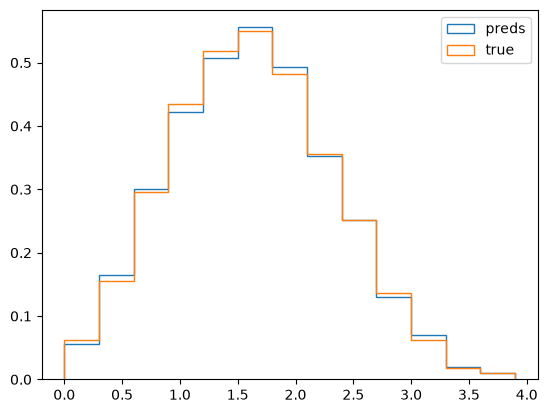

In [27]:
import matplotlib.pyplot as plt
import numpy as np

plt.hist(res, bins=np.arange(0,4,0.3), density=True, histtype='step', label='preds')
plt.hist(y_test, bins=np.arange(0,4,0.3), density=True, histtype='step', label='true')
plt.legend()
plt.show()

In [28]:
hist, _ = np.histogram(res, bins=np.arange(0,4,0.3), density=True)
hist_true, _ = np.histogram(y_test, bins=np.arange(0,4,0.3), density=True)

In [29]:
((hist - hist_true)**2).mean() * 1e3

np.float64(0.058575504907788734)

In [35]:
training_config

BNNTrainingConfig(device='cuda', batch_size=256, learning_rate=0.001, n_epochs=400, early_stopping_patience=50, min_delta=0.0, mode='min', factor=0.1, scheduler_patience=10)